In [75]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC, SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
)

TARGET = "JobSatLevel"
TARGET_ORDER = ["Low", "Average", "High"]


In [76]:
train = pd.read_csv("final_train_data.csv")
test = pd.read_csv("final_test_data.csv")

print("Train shape:", train.shape)
print("Test shape:", test.shape)
print("Train columns:", train.columns[:5].tolist(), "...")


Train shape: (19168, 80)
Test shape: (4793, 80)
Train columns: ['NewRole_I have neither consider or transitioned into a new career or industry', 'NewRole_I have strongly considered changing my career and/or the industry I work in', 'NewRole_I have somewhat considered changing my career and/or the industry I work in', 'AIThreat_No', 'AIModelsAdmired;openAI Image generating models'] ...


In [77]:
x_train = train.drop(columns=[TARGET]).copy()
y_train = train[TARGET].copy()

x_test = test.drop(columns=[TARGET]).copy()
y_test = test[TARGET].copy()

# Convert any remaining non-numeric feature columns safely.
# If all columns are already numeric, this changes nothing important.
combined_x = pd.concat([x_train, x_test], axis=0)
combined_x = pd.get_dummies(combined_x, dummy_na=True)

x_train = combined_x.iloc[:len(x_train)].copy()
x_test = combined_x.iloc[len(x_train):].copy()

# Make sure columns are exactly aligned and numeric.
x_train, x_test = x_train.align(x_test, join="left", axis=1, fill_value=0)
x_train = x_train.apply(pd.to_numeric, errors="coerce").fillna(0)
x_test = x_test.apply(pd.to_numeric, errors="coerce").fillna(0)

print("x_train:", x_train.shape)
print("x_test:", x_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)


x_train: (19168, 79)
x_test: (4793, 79)
y_train: (19168,)
y_test: (4793,)


## Evaluation helper

This fixes the confusion-matrix error by using labels that actually match the current target format.

In [78]:

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

def evaluate_classifier(model_name, model):
    target_order = [0, 1, 2]

    t0 = time.time()
    model.fit(x_train, y_train)
    train_time = time.time() - t0

    preds = model.predict(x_test)

    print(model_name)
    print(f"Train time: {train_time:.2f}s")
    print(f"Accuracy: {accuracy_score(y_test, preds):.4f}")
    print(f"Balanced accuracy: {balanced_accuracy_score(y_test, preds):.4f}")
    print(f"Macro F1: {f1_score(y_test, preds, average='macro'):.4f}")

    print(classification_report(
        y_test,
        preds,
        labels=target_order,
        target_names=["0", "1", "2"],
        zero_division=0
    ))

    cm = confusion_matrix(y_test, preds, labels=target_order)

    plt.figure(figsize=(6, 4))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        xticklabels=target_order,
        yticklabels=target_order
    )
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title(f"{model_name} — Confusion Matrix")
    plt.tight_layout()
    plt.show()

    return model, preds

## Logistic Regression

Logistic Regression
Train time: 0.52s
Accuracy: 0.5212
Balanced accuracy: 0.4454
Macro F1: 0.4412
              precision    recall  f1-score   support

           0       0.55      0.38      0.45      1361
           1       0.51      0.79      0.62      2259
           2       0.53      0.17      0.25      1173

    accuracy                           0.52      4793
   macro avg       0.53      0.45      0.44      4793
weighted avg       0.53      0.52      0.48      4793



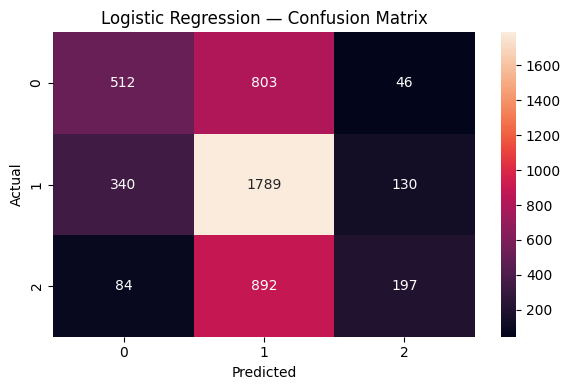

(LogisticRegression(max_iter=1000),
 array([0, 2, 1, ..., 1, 1, 1], shape=(4793,)))

In [79]:
log_reg = LogisticRegression(max_iter=1000)


evaluate_classifier(
    "Logistic Regression",
    log_reg,
)


## Linear SVM

Linear SVM
Train time: 2.41s
Accuracy: 0.5064
Balanced accuracy: 0.4945
Macro F1: 0.4942
              precision    recall  f1-score   support

           0       0.50      0.51      0.51      1361
           1       0.55      0.54      0.55      2259
           2       0.43      0.43      0.43      1173

    accuracy                           0.51      4793
   macro avg       0.49      0.49      0.49      4793
weighted avg       0.51      0.51      0.51      4793



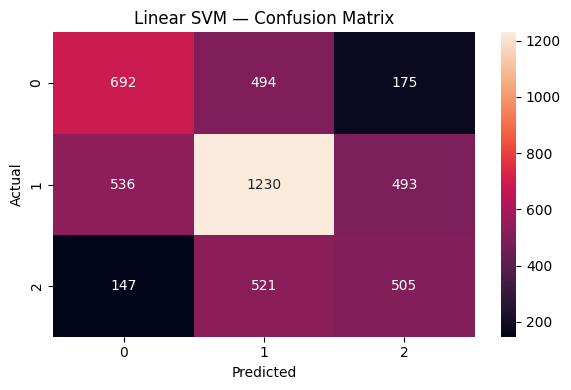

(Pipeline(steps=[('standardscaler', StandardScaler(with_mean=False)),
                 ('linearsvc',
                  LinearSVC(class_weight='balanced', max_iter=10000,
                            random_state=42))]),
 array([0, 2, 1, ..., 2, 1, 1], shape=(4793,)))

In [80]:
linear_svm = make_pipeline(
    StandardScaler(with_mean=False),
    LinearSVC(
        C=1.0,
        class_weight="balanced",
        random_state=42,
        max_iter=10000,
    ),
)

evaluate_classifier(
    "Linear SVM",
    linear_svm,
)


## Decision Tree

Decision Tree
Train time: 0.57s
Accuracy: 0.4515
Balanced accuracy: 0.4736
Macro F1: 0.4536
              precision    recall  f1-score   support

           0       0.46      0.52      0.49      1361
           1       0.52      0.37      0.43      2259
           2       0.38      0.53      0.44      1173

    accuracy                           0.45      4793
   macro avg       0.45      0.47      0.45      4793
weighted avg       0.47      0.45      0.45      4793



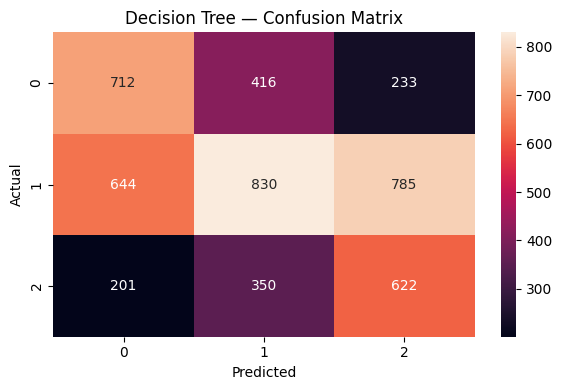

(DecisionTreeClassifier(class_weight='balanced', max_depth=8, random_state=42),
 array([0, 1, 2, ..., 2, 1, 2], shape=(4793,)))

In [81]:
from sklearn.tree import DecisionTreeClassifier

decision_tree = DecisionTreeClassifier(
    max_depth=8,
    random_state=42,
    class_weight="balanced",
)

evaluate_classifier(
    "Decision Tree",
    decision_tree,
)

# XGboost

XGBoost
Train time: 6.43s
Accuracy: 0.5312
Balanced accuracy: 0.4541
Macro F1: 0.4521
              precision    recall  f1-score   support

           0       0.57      0.37      0.45      1361
           1       0.52      0.81      0.63      2259
           2       0.55      0.18      0.27      1173

    accuracy                           0.53      4793
   macro avg       0.55      0.45      0.45      4793
weighted avg       0.54      0.53      0.49      4793



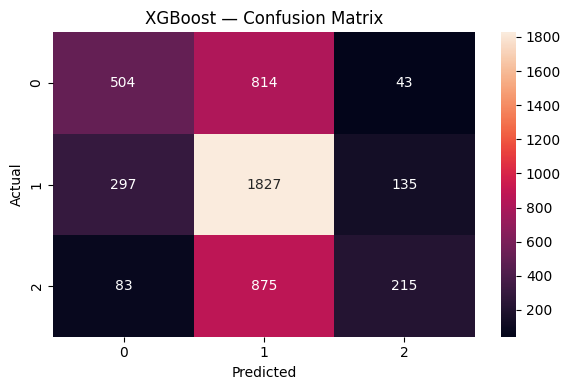

(XGBClassifier(base_score=None, booster=None, callbacks=None,
               colsample_bylevel=None, colsample_bynode=None,
               colsample_bytree=None, device=None, early_stopping_rounds=None,
               enable_categorical=False, eval_metric=None, feature_types=None,
               feature_weights=None, gamma=None, grow_policy=None,
               importance_type=None, interaction_constraints=None,
               learning_rate=0.05, max_bin=None, max_cat_threshold=None,
               max_cat_to_onehot=None, max_delta_step=None, max_depth=4,
               max_leaves=None, min_child_weight=None, missing=nan,
               monotone_constraints=None, multi_strategy=None, n_estimators=200,
               n_jobs=None, num_parallel_tree=None, ...),
 array([0, 1, 2, ..., 2, 1, 1], shape=(4793,)))

In [82]:
from xgboost import XGBClassifier

xgboost_model = XGBClassifier(
    n_estimators=200,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    random_state=42,
)

evaluate_classifier(
    "XGBoost",
    xgboost_model
)

## Baseline Random Forest

Baseline Random Forest
Train time: 3.27s
Accuracy: 0.4765
Balanced accuracy: 0.4974
Macro F1: 0.4782
              precision    recall  f1-score   support

           0       0.48      0.56      0.52      1361
           1       0.54      0.39      0.46      2259
           2       0.40      0.53      0.46      1173

    accuracy                           0.48      4793
   macro avg       0.48      0.50      0.48      4793
weighted avg       0.49      0.48      0.48      4793



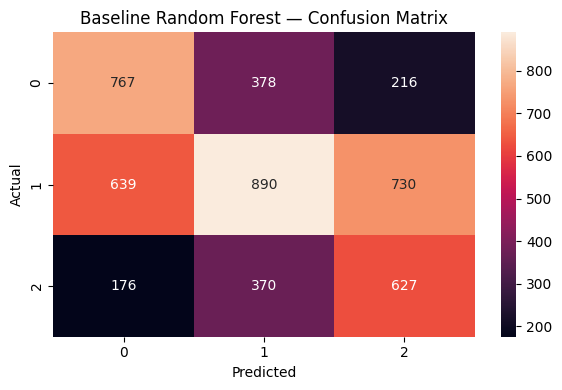

In [83]:
baseline_rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=12,
    random_state=42,
    n_jobs=-1,
    class_weight="balanced",
)

t0 = time.time()
baseline_rf.fit(x_train, y_train)
train_time = time.time() - t0

preds = baseline_rf.predict(x_test)

target_order = [0, 1, 2]

print("Baseline Random Forest")
print(f"Train time: {train_time:.2f}s")
print(f"Accuracy: {accuracy_score(y_test, preds):.4f}")
print(f"Balanced accuracy: {balanced_accuracy_score(y_test, preds):.4f}")
print(f"Macro F1: {f1_score(y_test, preds, average='macro'):.4f}")

print(classification_report(
    y_test,
    preds,
    labels=target_order,
    target_names=["0", "1", "2"]
))

cm = confusion_matrix(y_test, preds, labels=target_order)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=target_order,
    yticklabels=target_order
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Baseline Random Forest — Confusion Matrix")
plt.tight_layout()
plt.show()

# Decision tree with cross validation

In [84]:
from sklearn.model_selection import (StratifiedKFold,cross_val_score)

RANDOM_STATE = 42

print("Train shape:", x_train.shape)
print("Test shape :", x_test.shape)

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)


tuning_results = {}
#decision tree
print("Decision Tree Classifier")

dt_max_depth_vals = [3, 5, 10, None]
dt_min_split_vals = [2, 5, 10]

best_dt_score = 0
best_dt_params = {}

#max depth
dt_depth_results = {}

for d in dt_max_depth_vals:

    clf = DecisionTreeClassifier(
        max_depth=d,
        min_samples_split=2,
        random_state=RANDOM_STATE
    )

    scores = cross_val_score(
        clf,
        x_train,
        y_train,
        cv=cv,
        scoring='accuracy',
        n_jobs=-1
    )

    mean_acc = scores.mean()

    dt_depth_results[str(d)] = mean_acc

    print(f"max_depth={d} --> CV Accuracy={mean_acc:.4f}")

# Best depth
best_dt_depth = dt_max_depth_vals[
    np.argmax(list(dt_depth_results.values()))
]

print("\nBest max_depth:", best_dt_depth)

#min split
dt_split_results = {}

for s in dt_min_split_vals:

    clf = DecisionTreeClassifier(
        max_depth=best_dt_depth,
        min_samples_split=s,
        random_state=RANDOM_STATE
    )

    scores = cross_val_score(
        clf,
        x_train,
        y_train,
        cv=cv,
        scoring='accuracy',
        n_jobs=-1
    )

    mean_acc = scores.mean()

    dt_split_results[str(s)] = mean_acc

    print(f"min_samples_split={s} --> CV Accuracy={mean_acc:.4f}")

# Best split
best_dt_split = dt_min_split_vals[
    np.argmax(list(dt_split_results.values()))
]

print("\nBest min_samples_split:", best_dt_split)

final_dt = DecisionTreeClassifier(
    max_depth=best_dt_depth,
    min_samples_split=best_dt_split,
    random_state=RANDOM_STATE
)

final_dt.fit(x_train, y_train)

dt_test_preds = final_dt.predict(x_test)

dt_test_acc = accuracy_score(y_test, dt_test_preds)

print("\nFINAL Decision Tree Test Accuracy:", dt_test_acc)

tuning_results["DecisionTree"] = {
    "max_depth": dt_depth_results,
    "min_samples_split": dt_split_results,
    "best_params": {
        "max_depth": best_dt_depth,
        "min_samples_split": best_dt_split
    },
    "test_accuracy": dt_test_acc
}


Train shape: (19168, 79)
Test shape : (4793, 79)
Decision Tree Classifier
max_depth=3 --> CV Accuracy=0.5042
max_depth=5 --> CV Accuracy=0.5091
max_depth=10 --> CV Accuracy=0.4805
max_depth=None --> CV Accuracy=0.4081

Best max_depth: 5
min_samples_split=2 --> CV Accuracy=0.5091
min_samples_split=5 --> CV Accuracy=0.5091
min_samples_split=10 --> CV Accuracy=0.5090

Best min_samples_split: 2

FINAL Decision Tree Test Accuracy: 0.5190903400792823


# RANDOM FOREST with cross validation

In [ ]:

# RANDOM FOREST
print("\n")
print("Random Forest Classifier")

rf_n_estimators_vals = [50, 100,200]
rf_max_depth_vals = [3, 5, 10, None]

best_rf_score = 0
best_rf_params = {}

rf_n_results = {}

for n in rf_n_estimators_vals:

    clf = RandomForestClassifier(
        n_estimators=n,
        max_depth=None,
        random_state=RANDOM_STATE,
        class_weight='balanced',
        n_jobs=-1
    )

    scores = cross_val_score(
        clf,
        x_train,
        y_train,
        cv=cv,
        scoring='accuracy',
        n_jobs=-1
    )

    mean_acc = scores.mean()

    rf_n_results[str(n)] = mean_acc

    print(f"n_estimators={n} --> CV Accuracy={mean_acc:.4f}")

# Best n_estimators
best_rf_n = rf_n_estimators_vals[
    np.argmax(list(rf_n_results.values()))
]

print("\nBest n_estimators:", best_rf_n)

rf_depth_results = {}

for d in rf_max_depth_vals:

    clf = RandomForestClassifier(
        n_estimators=best_rf_n,
        max_depth=d,
        random_state=RANDOM_STATE,
        class_weight='balanced',
        n_jobs=-1
    )

    scores = cross_val_score(
        clf,
        x_train,
        y_train,
        cv=cv,
        scoring='accuracy',
        n_jobs=-1
    )

    mean_acc = scores.mean()

    rf_depth_results[str(d)] = mean_acc

    print(f"max_depth={d} --> CV Accuracy={mean_acc:.4f}")

best_rf_depth = rf_max_depth_vals[
    np.argmax(list(rf_depth_results.values()))
]

print("\nBest max_depth:", best_rf_depth)

final_rf = RandomForestClassifier(
    n_estimators=best_rf_n,
    max_depth=best_rf_depth,
    random_state=RANDOM_STATE,
    class_weight='balanced',
    n_jobs=-1
)

final_rf.fit(x_train, y_train)

rf_test_preds = final_rf.predict(x_test)

rf_test_acc = accuracy_score(y_test, rf_test_preds)

print("\nFINAL Random Forest Test Accuracy:", rf_test_acc)
tuning_results["RandomForest"] = {
    "n_estimators": rf_n_results,
    "max_depth": rf_depth_results,
    "best_params": {
        "n_estimators": best_rf_n,
        "max_depth": best_rf_depth
    },
    "test_accuracy": rf_test_acc
}


print("FINAL RESULTS")
for model_name, results in tuning_results.items():

    print(f"\n{model_name}")

    print("Best Parameters:")
    print(results["best_params"])

    print("Test Accuracy:")
    print(round(results["test_accuracy"], 4))



Random Forest Classifier
n_estimators=50 --> CV Accuracy=0.5067
n_estimators=100 --> CV Accuracy=0.5134
n_estimators=200 --> CV Accuracy=0.5151

Best n_estimators: 200
max_depth=3 --> CV Accuracy=0.3974
max_depth=5 --> CV Accuracy=0.4196
max_depth=10 --> CV Accuracy=0.4535
max_depth=None --> CV Accuracy=0.5151

Best max_depth: None

FINAL Random Forest Test Accuracy: 0.5259753807636136
FINAL RESULTS

DecisionTree
Best Parameters:
{'max_depth': 5, 'min_samples_split': 2}
Test Accuracy:
0.5191

RandomForest
Best Parameters:
{'n_estimators': 200, 'max_depth': None}
Test Accuracy:
0.526


,model,train_time_sec,accuracy,balanced_accuracy,macro_f1
4,Decision Tree with CV,0.330868,0.519090,0.432917,0.424548
2,Decision Tree,1.040515,0.451492,0.473609,0.453616
3,Random Forest,3.481815,0.476528,0.497354,0.478221
1,Linear SVM,3.567508,0.506363,0.494486,0.494183
5,Random Forest with CV,4.413640,0.525975,0.437130,0.422196
0,Logistic Regression,6.782877,0.521177,0.445361,0.441223
6,XGBoost,8.979507,0.531191,0.454124,0.452103


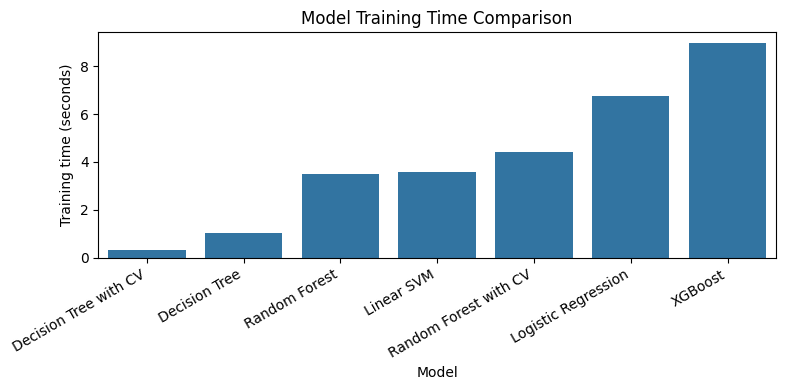

In [86]:
from sklearn.base import clone

models_for_timing = {
    "Logistic Regression": log_reg,
    "Linear SVM": linear_svm,
    "Decision Tree": decision_tree,
    "Random Forest": baseline_rf,
    "Decision Tree with CV": final_dt,
    "Random Forest with CV": final_rf,
    "XGBoost" : xgboost_model,
}

timing_results = []

for model_name, model in models_for_timing.items():
    model_to_fit = clone(model)

    t0 = time.time()
    model_to_fit.fit(x_train, y_train)
    train_time = time.time() - t0

    preds = model_to_fit.predict(x_test)

    timing_results.append({
        "model": model_name,
        "train_time_sec": train_time,
        "accuracy": accuracy_score(y_test, preds),
        "balanced_accuracy": balanced_accuracy_score(y_test, preds),
        "macro_f1": f1_score(y_test, preds, average="macro"),
    })

timing_df = pd.DataFrame(timing_results).sort_values("train_time_sec")
display(timing_df)

plt.figure(figsize=(8, 4))
sns.barplot(data=timing_df, x="model", y="train_time_sec")
plt.xlabel("Model")
plt.ylabel("Training time (seconds)")
plt.title("Model Training Time Comparison")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


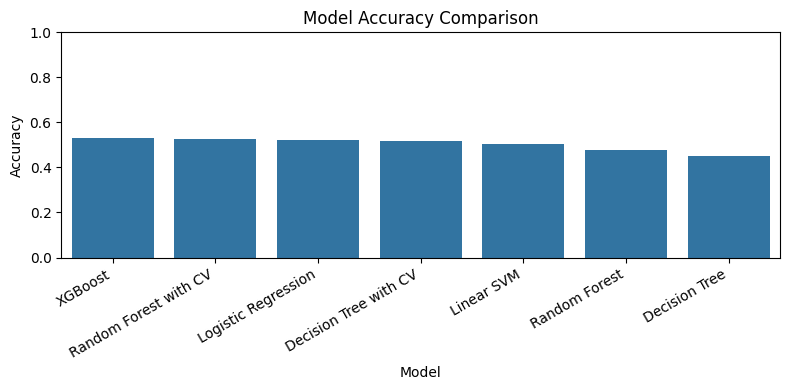

In [87]:
plt.figure(figsize=(8, 4))

sns.barplot(
    data=timing_df.sort_values("accuracy", ascending=False),
    x="model",
    y="accuracy"
)

plt.xlabel("Model")
plt.ylabel("Accuracy")
plt.title("Model Accuracy Comparison")
plt.ylim(0, 1)
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

,model,test_time_sec,accuracy,balanced_accuracy,macro_f1
0,Logistic Regression,0.005744,0.521177,0.445361,0.441223
4,Decision Tree with CV,0.007592,0.519090,0.432917,0.424548
2,Decision Tree,0.015045,0.451492,0.473609,0.453616
1,Linear SVM,0.029303,0.506363,0.494486,0.494183
6,XGBoost,0.032862,0.531191,0.454124,0.452103
3,Random Forest,0.374772,0.476528,0.497354,0.478221
5,Random Forest with CV,0.389396,0.525975,0.437130,0.422196


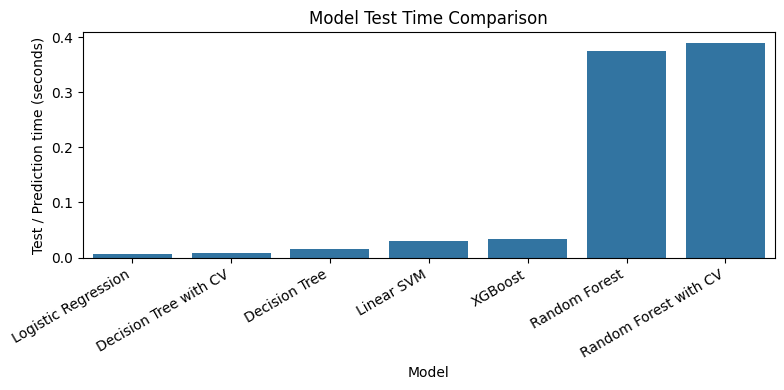

In [88]:
# Measure test / prediction time for each model
test_time_results = []

for model_name, model in models_for_timing.items():
    model_to_fit = clone(model)

    # Fit the model first
    model_to_fit.fit(x_train, y_train)

    # Measure prediction time only
    t0 = time.time()
    preds = model_to_fit.predict(x_test)
    test_time = time.time() - t0

    test_time_results.append({
        "model": model_name,
        "test_time_sec": test_time,
        "accuracy": accuracy_score(y_test, preds),
        "balanced_accuracy": balanced_accuracy_score(y_test, preds),
        "macro_f1": f1_score(y_test, preds, average="macro"),
    })

test_time_df = pd.DataFrame(test_time_results).sort_values("test_time_sec")

display(test_time_df)


# Bar graph: Test / prediction time comparison
plt.figure(figsize=(8, 4))

sns.barplot(
    data=test_time_df,
    x="model",
    y="test_time_sec"
)

plt.xlabel("Model")
plt.ylabel("Test / Prediction time (seconds)")
plt.title("Model Test Time Comparison")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

In [89]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score
import pandas as pd
import time


results = []


def run_svm_experiment(param_name, param_values):
    fixed_params = {
        "C": 1.0,
        "class_weight": "balanced",
        "random_state": 42,
        "max_iter": 5000
    }

    for value in param_values:
        params = fixed_params.copy()
        params[param_name] = value

        model = Pipeline([
            ("scaler", StandardScaler(with_mean=False)),
            ("svm", LinearSVC(**params))
        ])

        t0 = time.time()
        model.fit(x_train, y_train)
        train_time = time.time() - t0

        preds = model.predict(x_test)

        results.append({
            "model": "Linear SVM",
            "changed_parameter": param_name,
            "value": value,
            "C": params["C"],
            "n_estimators": None,
            "train_time_sec": train_time,
            "accuracy": accuracy_score(y_test, preds),
            "balanced_accuracy": balanced_accuracy_score(y_test, preds),
            "macro_f1": f1_score(y_test, preds, average="macro")
        })


def run_random_forest_experiment(param_name, param_values):
    fixed_params = {
        "n_estimators": 200,
        "max_depth": 12,
        "random_state": 42,
        "n_jobs": -1,
        "class_weight": "balanced"
    }

    for value in param_values:
        params = fixed_params.copy()
        params[param_name] = value

        model = RandomForestClassifier(**params)

        t0 = time.time()
        model.fit(x_train, y_train)
        train_time = time.time() - t0

        preds = model.predict(x_test)

        results.append({
            "model": "Random Forest",
            "changed_parameter": param_name,
            "value": value,
            "C": None,
            "n_estimators": params["n_estimators"],
            "train_time_sec": train_time,
            "accuracy": accuracy_score(y_test, preds),
            "balanced_accuracy": balanced_accuracy_score(y_test, preds),
            "macro_f1": f1_score(y_test, preds, average="macro")
        })


run_svm_experiment(
    param_name="C",
    param_values=[0.1, 1, 10]
)

run_random_forest_experiment(
    param_name="n_estimators",
    param_values=[100, 200, 300]
)


results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    ["macro_f1", "balanced_accuracy"],
    ascending=False
).reset_index(drop=True)

display(results_df)

,model,changed_parameter,value,C,n_estimators,train_time_sec,accuracy,balanced_accuracy,macro_f1
0,Linear SVM,C,0.1,0.1,NaN,2.215573,0.506363,0.494486,0.494183
1,Linear SVM,C,1.0,1.0,NaN,2.115430,0.506363,0.494486,0.494183
2,Linear SVM,C,10.0,10.0,NaN,2.237385,0.506363,0.494486,0.494183
3,Random Forest,n_estimators,200.0,NaN,200.0,3.098334,0.476528,0.497354,0.478221
4,Random Forest,n_estimators,300.0,NaN,300.0,5.512836,0.476111,0.496082,0.477523
5,Random Forest,n_estimators,100.0,NaN,100.0,1.751147,0.468809,0.490547,0.470753


In [90]:

import pickle
from pathlib import Path

Path("preprocessing_objects").mkdir(exist_ok=True)

models = {}

# Base models

models["logistic_regression"] = log_reg

models["linear_svm"] = linear_svm

models["decision_tree"] = decision_tree

models["random_forest"] = baseline_rf

models["decision_tree_cv"] = final_dt

models["random_forest_cv"] = final_rf

models["XGBoost"] = xgboost_model

model_data = {
    "models": models,
    "model_feature_columns": list(x_train.columns),
    "target_col": TARGET,
}

with open("preprocessing_objects/models.pkl", "wb") as f:
    pickle.dump(model_data, f)

print("Saved models to preprocessing_objects/models.pkl")
print("Models saved:", list(models.keys()))


Saved models to preprocessing_objects/models.pkl
Models saved: ['logistic_regression', 'linear_svm', 'decision_tree', 'random_forest', 'decision_tree_cv', 'random_forest_cv', 'XGBoost']
